# Introduction to Graphs and Graph Neural Networks

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import seaborn as snss
import pandas as pd
plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.direction'] = 'in'
plt.rcParams['axes.grid'] = True
plt.rcParams['axes.axisbelow'] = True
plt.rcParams['figure.dpi'] = 150

In [2]:
# Check available hardware
import torch
if torch.cuda.is_available():
    print(f'GPU is available, using GPU {torch.cuda.get_device_name(0)}')
    device = torch.device('cuda')
elif torch.mps.is_available():
    print(f'Apple Metal Performance Shaders framework is available, using {torch.device("mps")}')
    device = torch.device('mps')
else:
    print(f'Hardware acceleration not available, using CPU')
    device = torch.device('cpu')

GPU is available, using GPU Tesla T4


## What is a graph?

A graph is a structure containing a set of **nodes** (also called **vertices**)  and **edges** that link between nodes. We denote the set of nodes/vertices as $V$ and the edges as $E \subseteq V \times V$. 

A graph $G = (V, E)$ is said to have order $n = |V|$ and size $s = |E|$. The degree $d$ of a particular vertex is given by the number of edges connected to it.

Nodes: [1, 2, 3, 4]
Edges: [(1, 2), (1, 3), (1, 4), (2, 3), (3, 4)]


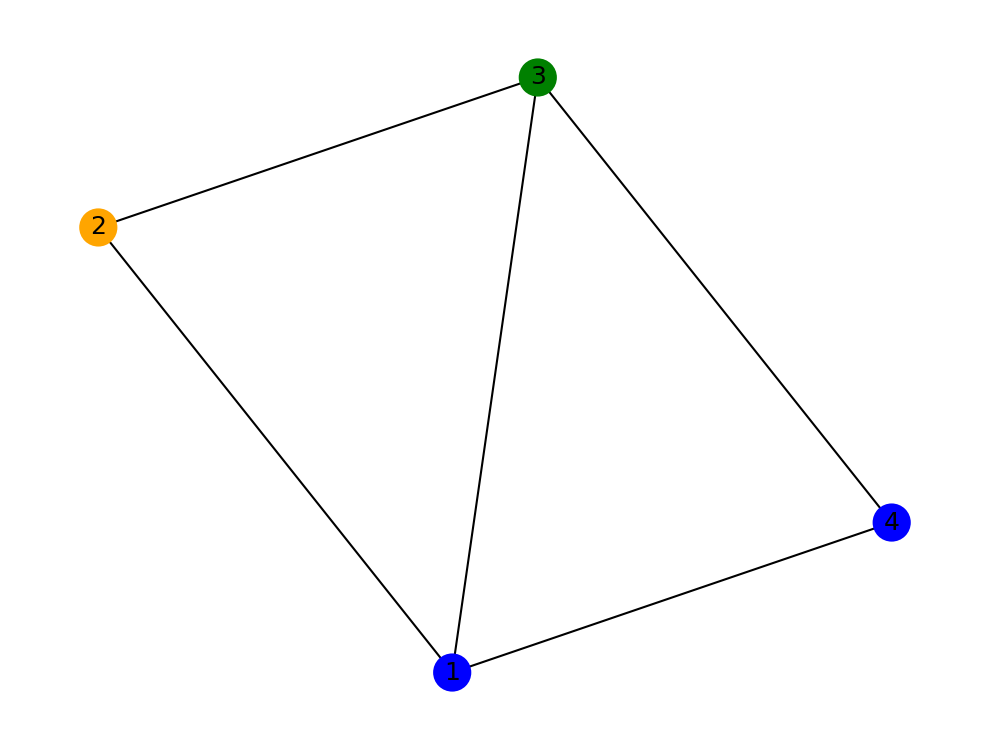

In [3]:
import networkx as nx

# Define a graph structure using NetworkX
G = nx.Graph()

# A graph has nodes, edges
G.add_nodes_from([
    (1, {'color': 'blue'}),
    (2, {'color': 'orange'}),
    (3, {'color': 'green'}),
    (4, {'color': 'blue'}),
])
print('Nodes:', G.nodes)

G.add_edges_from([
    (1, 2),
    (2, 3),
    (1, 3),
    (1, 4),
    (3, 4),
])
print('Edges:', G.edges)

nx.draw(G, with_labels=True, node_color=nx.get_node_attributes(G, 'color').values())

In [6]:
nx.get_node_attributes(G, 'color')

{1: 'blue', 2: 'orange', 3: 'green', 4: 'blue'}

### Adjacency matrix

The connections in a graph can be defined using an adjacency matrix $A$. The entries $A_{ij}$ are nonzero if there is an edge between vertices $i$ and $j$. For a simple undirected graph, the adjacency matrix must be symmetric $A_{ij} = A_{ji}$. 

In [4]:
A = np.asarray(nx.adjacency_matrix(G).todense())
print('Adjacency matrix')
print(A)

Adjacency matrix
[[0 1 1 1]
 [1 0 1 0]
 [1 1 0 1]
 [1 0 1 0]]


### Nodes can have values (features)

Beyond just specifying connections between elements, graph nodes can contain information encoded in a feature vector $\mathbf{x}$. Below, see an example where each node contains a scalar feature.

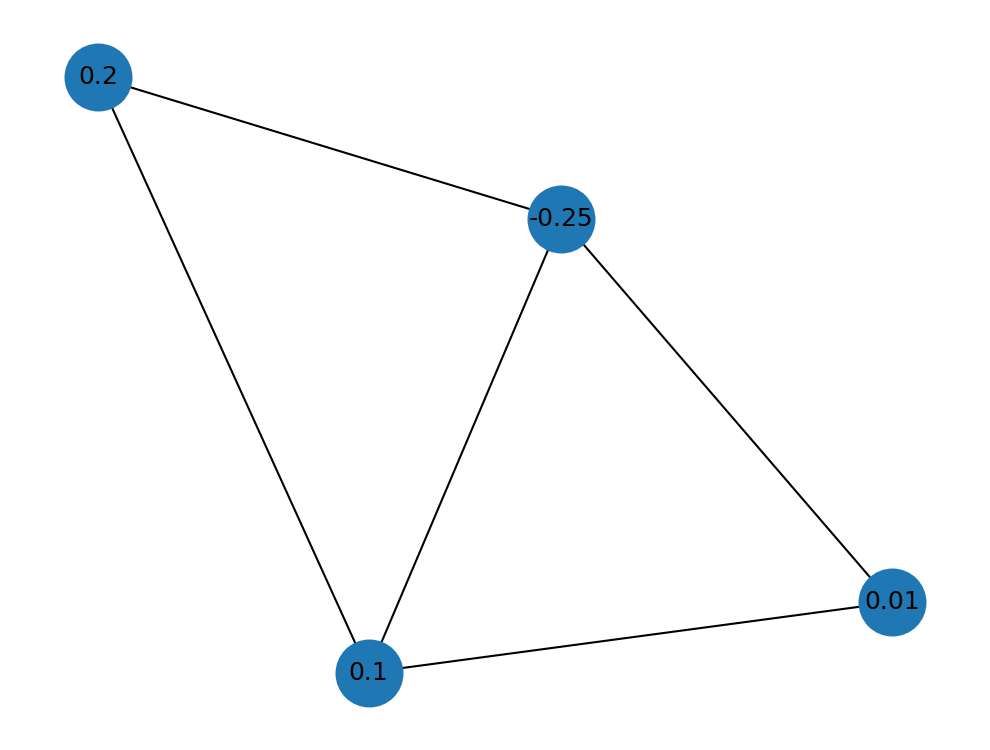

In [7]:
# Nodes can have features/values
G.add_nodes_from([
    (1, {'color': 'blue', 'feature': 0.1}),
    (2, {'color': 'orange', 'feature': 0.2}),
    (3, {'color': 'green', 'feature': -0.25}),
    (4, {'color': 'blue', 'feature': 0.01}),
])
nx.draw(G, labels=nx.get_node_attributes(G, 'feature'), node_size=1e3)

In [13]:
G.nodes

NodeView((1, 2, 3, 4))

In [9]:
nx.get_node_attributes(G, 'feature')

{1: 0.1, 2: 0.2, 3: -0.25, 4: 0.01}

In [10]:
[feature for node, feature in nx.get_node_attributes(G, 'feature').items()]

[0.1, 0.2, -0.25, 0.01]

### Edges can have values (weights)

Likewise, edges in a graph can have features, which are sometimes interpreted as weights on each connection. See example below

In [12]:
G.edges

EdgeView([(1, 2), (1, 3), (1, 4), (2, 3), (3, 4)])

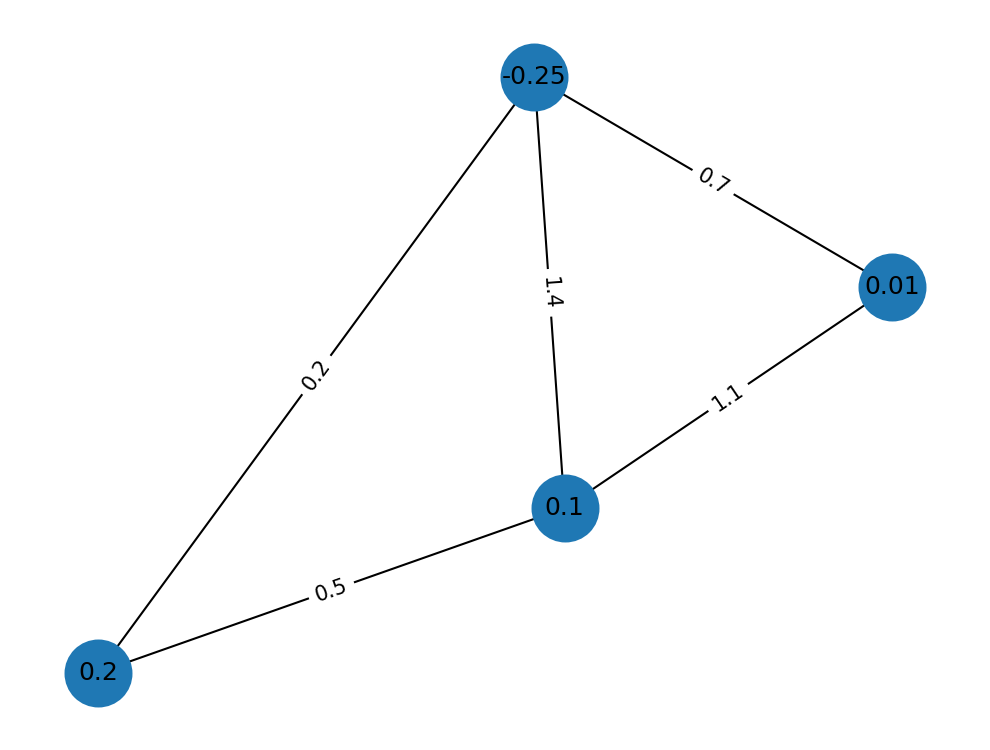

In [14]:
# Edges can have features/values
G.add_edges_from([
    (1, 2, {'weight': 0.5}),
    (2, 3, {'weight': 0.2}),
    (1, 3, {'weight': 1.4}),
    (1, 4, {'weight': 1.1}),
    (3, 4, {'weight': 0.7}),
])
pos = nx.spring_layout(G)
nx.draw(G, pos, labels=nx.get_node_attributes(G, 'feature'), node_size=1e3)
nx.draw_networkx_edge_labels(G,pos, edge_labels=nx.get_edge_attributes(G, 'weight'));

In [8]:
nx.get_edge_attributes(G, 'weight')

{(1, 2): 0.5, (1, 3): 1.4, (1, 4): 1.1, (2, 3): 0.2, (3, 4): 0.7}

In [15]:
[feature for edge, feature in nx.get_edge_attributes(G, 'weight')]

[2, 3, 4, 3, 4]

### Graph edges can be *directed*

For directed graphs (or *digraphs*), edges are unidirectional

In [ ]:
# Graphs can be directed
import networkx as nx

D = nx.DiGraph()

# A graph has nodes, edges
D.add_nodes_from([
    (1, {'color': 'blue'}),
    (2, {'color': 'orange'}),
    (3, {'color': 'green'}),
    (4, {'color': 'blue'}),
])
print('Nodes:', D.nodes)

D.add_edges_from([
    (1, 2),
    (2, 1),
    (2, 3),
    (1, 3),
    (1, 4),
    (4, 1),
    (3, 4),
])
print('Edges:', D.edges)

nx.draw(D, with_labels=True, node_color=nx.get_node_attributes(D, 'color').values())

In [ ]:
# Directed graphs can have unique features on each directed edge
D.add_edges_from([
    (1, 2, {'weight': 0.5}),
    (2, 1, {'weight': 1.4}),
    (2, 3, {'weight': 0.2}),
    (1, 3, {'weight': 1.4}),
    (1, 4, {'weight': 1.1}),
    (4, 1, {'weight': -1.1}),
    (3, 4, {'weight': 0.7}),
])
ax = plt.figure().gca()
pos = nx.spring_layout(D)
nx.draw_networkx_nodes(D, pos, node_size=1e3, ax=ax)

connectionstyle=[f"arc3,rad=0.15", f"arc3,rad=0.3"]
nx.draw_networkx_edges(D, pos, arrows=True, arrowstyle='-|>', arrowsize=25, connectionstyle=connectionstyle);
nx.draw_networkx_edge_labels(D,pos, edge_labels=nx.get_edge_attributes(D, 'weight'),
                             connectionstyle=connectionstyle)

plt.gca().axis('off')
                            

In this case the adjancy matrix no longer has to be symmetric!

In [ ]:
A = np.asarray(nx.adjacency_matrix(D).todense())
print('Adjacency matrix')
print(A)

## Concrete examples

## Graph convolution

Let's start by reviewing some of the key concepts from convolutional neural networks. CNNs leverage parameter sharing and sparse connectivity to achieve **translation equivariance**. Using local pooling, they can achieve local **translation invariance** as well. Finally, CNNs learn a hierarchy of features, starting with basic objects like edges and corners in early layers, followed by more complex features in later layers.

Beyond those properties, CNNs are computationally efficient. Their weight sharing means they have a smaller footprint than an FCNN applied to similar data, and the convolution operation can be applied to inputs of arbitrary spatial dimension. That is, a CNN trained on $224 \times 224$ images can be applied to $28 \times 28$ images. 

To develop graph convolution, it would be nice to leverage these notions of parameter sharing, sparse connectivity, and some equivariance property. 

### Permutation equivariance

Graph data does not require translation invariance, because there is no notion of spatial position. And parameter sharing becomes more challenging when the number of neighbors for each node is not constant. The only things graphs have are node features, adjacency matrix, and optionally edge features. They also require **permutation equivariant** - if the order of the nodes are scrambled, the output should be scrambled in the same way, but otherwise should not change.

$$ f(Px ) = P f(x) $$

In [19]:
# Permutation invariance means that an operation should give the same outputs for the following three graphs
import networkx as nx

G1 = nx.Graph()

# A graph has nodes, edges
G1.add_nodes_from([
    ('A', {'color': 'blue'}),
    ('B', {'color': 'orange'}),
    ('C', {'color': 'green'}),
    ('D', {'color': 'red'}),
])
print('Nodes:', G1.nodes)

G1.add_edges_from([
    ('A', 'B'),
    ('B', 'C'),
    ('A', 'C'),
    ('C', 'D'),
])
print('Edges:', G1.edges)
print('Adjacency Matrix:\n', np.asarray(nx.adjacency_matrix(G1).todense()))

Nodes: ['A', 'B', 'C', 'D']
Edges: [('A', 'B'), ('A', 'C'), ('B', 'C'), ('C', 'D')]
Adjacency Matrix:
 [[0 1 1 0]
 [1 0 1 0]
 [1 1 0 1]
 [0 0 1 0]]


In [20]:
# Permutation invariance means that an operation should give the same outputs for the following three graphs
import networkx as nx

G2 = nx.Graph()

# A graph has nodes, edges
G2.add_nodes_from([
    ('C', {'color': 'green'}),
    ('B', {'color': 'orange'}),
    ('D', {'color': 'red'}),
    ('A', {'color': 'blue'}),
])
print('Nodes:', G2.nodes)

G2.add_edges_from([
    ('A', 'B'),
    ('B', 'C'),
    ('A', 'C'),
    ('C', 'D'),
])
print('Edges:', G2.edges)
print('Adjacency Matrix:\n', np.asarray(nx.adjacency_matrix(G2).todense()))

Nodes: ['C', 'B', 'D', 'A']
Edges: [('C', 'B'), ('C', 'A'), ('C', 'D'), ('B', 'A')]
Adjacency Matrix:
 [[0 1 1 1]
 [1 0 0 1]
 [1 0 0 0]
 [1 1 0 0]]


In [21]:
# Permutation invariance means that an operation should give the same outputs for the following three graphs
import networkx as nx

G3 = nx.Graph()

# A graph has nodes, edges
G3.add_nodes_from([
    ('B', {'color': 'orange'}),
    ('A', {'color': 'blue'}),
    ('D', {'color': 'red'}),
    ('C', {'color': 'green'}),
])
print('Nodes:', G3.nodes)

G3.add_edges_from([
    ('A', 'B'),
    ('B', 'C'),
    ('A', 'C'),
    ('C', 'D'),
])
print('Edges:', G3.edges)
print('Adjacency Matrix:\n', np.asarray(nx.adjacency_matrix(G3).todense()))

Nodes: ['B', 'A', 'D', 'C']
Edges: [('B', 'A'), ('B', 'C'), ('A', 'C'), ('D', 'C')]
Adjacency Matrix:
 [[0 1 0 1]
 [1 0 0 1]
 [0 0 0 1]
 [1 1 1 0]]


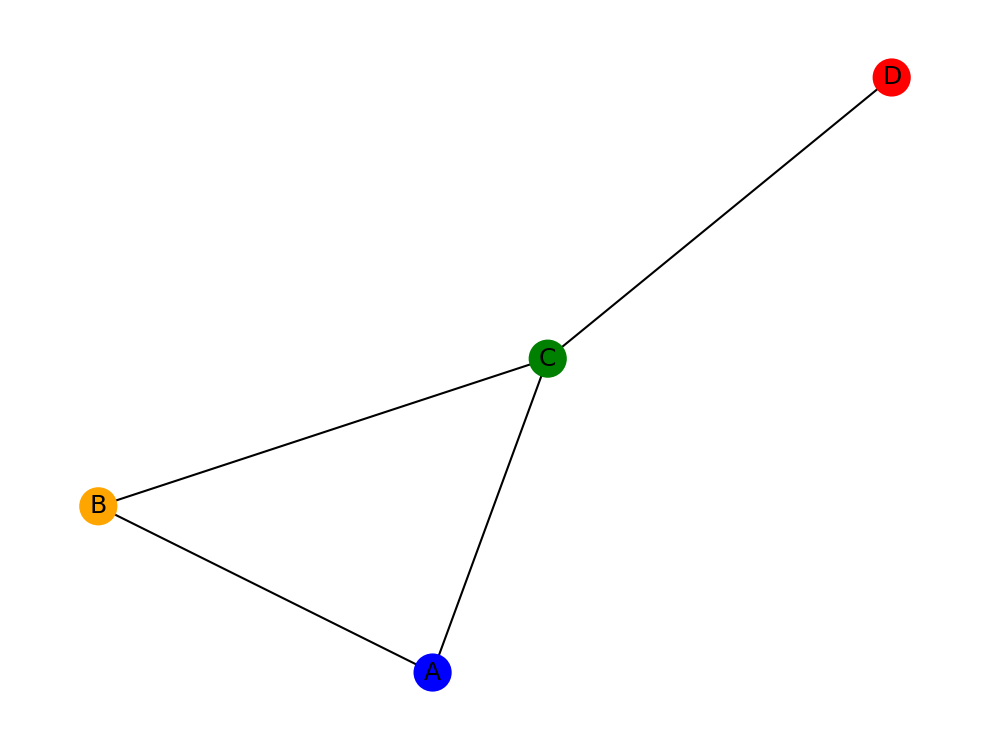

In [22]:
nx.draw(G1, with_labels=True, node_color=nx.get_node_attributes(G1, 'color').values())

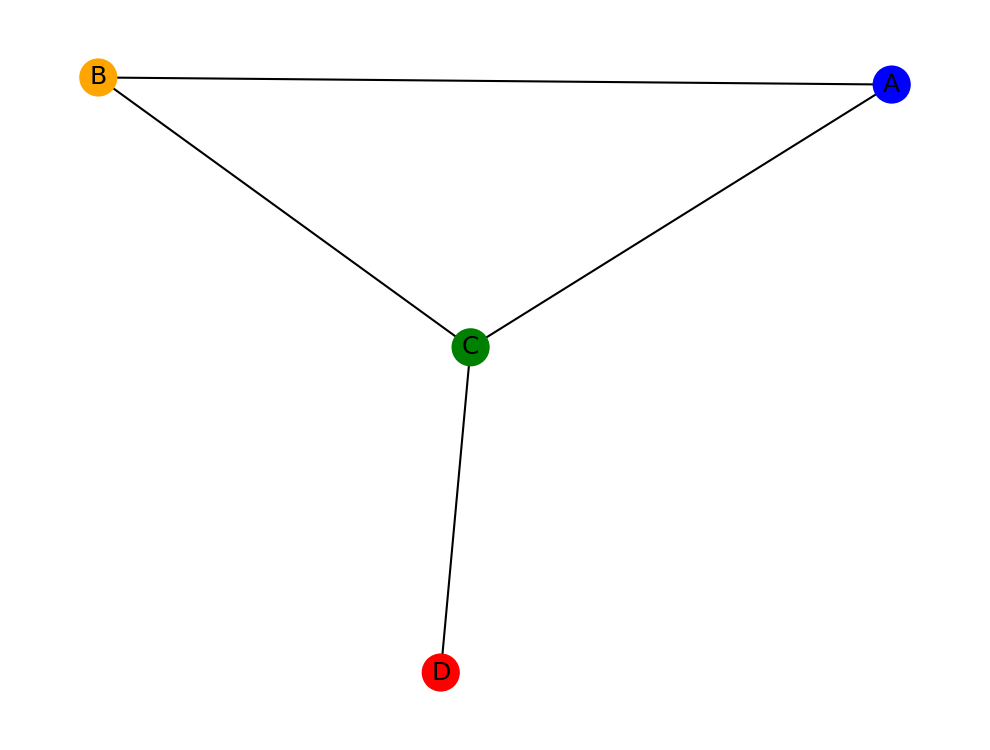

In [23]:
nx.draw(G2, with_labels=True, node_color=nx.get_node_attributes(G2, 'color').values())

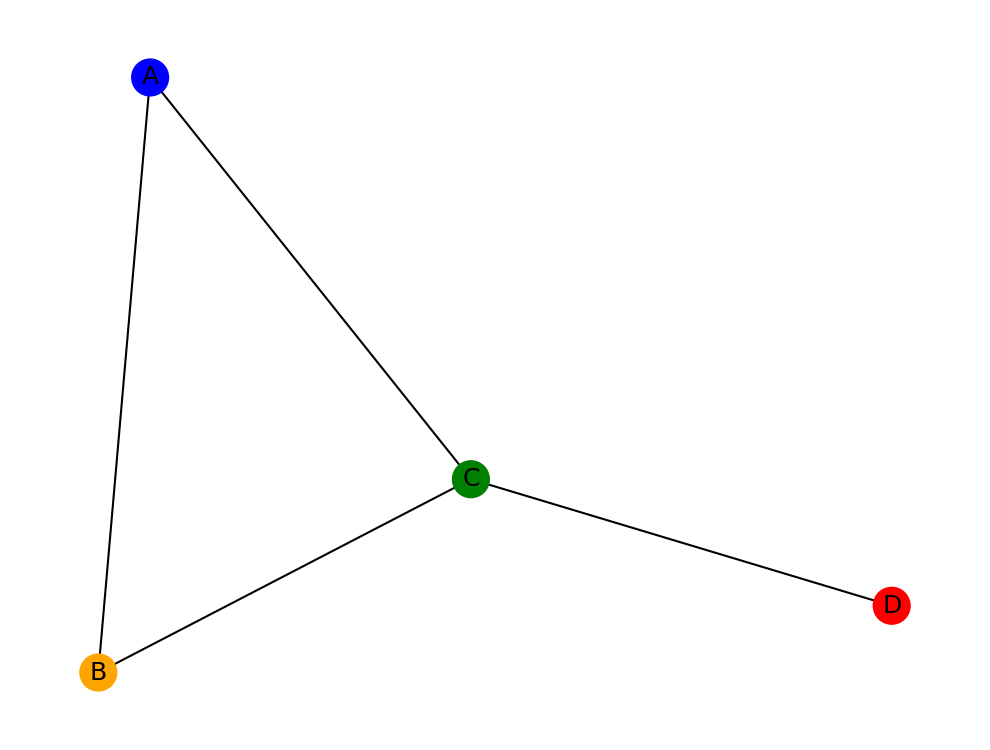

In [24]:
nx.draw(G3, with_labels=True, node_color=nx.get_node_attributes(G3, 'color').values())

In [25]:
feature_map = {
    'red': 0,
    'green': 1,
    'blue': 2,
    'orange': 3
}

def get_one_hot_features(G):
    features = np.array([feature_map[v] for v in nx.get_node_attributes(G, 'color').values()])
    one_hot = np.zeros([features.shape[0], len(np.unique(features))])
    one_hot[np.arange(len(one_hot)), features] = 1.
    return one_hot

print(get_one_hot_features(G1))
print(get_one_hot_features(G2))
print(get_one_hot_features(G3))

[[0. 0. 1. 0.]
 [0. 0. 0. 1.]
 [0. 1. 0. 0.]
 [1. 0. 0. 0.]]
[[0. 1. 0. 0.]
 [0. 0. 0. 1.]
 [1. 0. 0. 0.]
 [0. 0. 1. 0.]]
[[0. 0. 0. 1.]
 [0. 0. 1. 0.]
 [1. 0. 0. 0.]
 [0. 1. 0. 0.]]


In [26]:
def print_nodes_features(nodes, features):
    for node, feat in zip(nodes, features):
        print(node, ':', feat)

print_nodes_features(G1.nodes(), get_one_hot_features(G1))
print()
print_nodes_features(G2.nodes(), get_one_hot_features(G2))
print()
print_nodes_features(G3.nodes(), get_one_hot_features(G3))

A : [0. 0. 1. 0.]
B : [0. 0. 0. 1.]
C : [0. 1. 0. 0.]
D : [1. 0. 0. 0.]

C : [0. 1. 0. 0.]
B : [0. 0. 0. 1.]
D : [1. 0. 0. 0.]
A : [0. 0. 1. 0.]

B : [0. 0. 0. 1.]
A : [0. 0. 1. 0.]
D : [1. 0. 0. 0.]
C : [0. 1. 0. 0.]


### A basic graph convolution

One option is to sum over the incoming features at each node to determine the updated feature value. We can apply a weight matrix $W_{ij}$ to each incoming feature, but it will be the same weight matrix. For example, the preactivation $\mathbf{z}_i$ at node $i$ will be

\begin{align*}
    \mathbf{z}_i &= \mathbf{b} +  \mathbf{x}_i \, \mathbf{W}_1+ \sum_{j \in \mathcal{N}(i)}  \mathbf{x}_j \, \mathbf{W}_2
\end{align*}

Here, $\mathbf{b}$ is a learnable bias, $\mathbf{W}_1$ is a matrix applied to the local feature, and $\mathbf{W}_2$ is a matrix applied to each neighbor node's feature. In principle, $\mathbf{W}_1,\mathbf{W}_2$ can be matrices of shape $f_{\text{in}} \times f_{\text{out}}$ to change the feature dimension at each update. 

The term $j \in \mathcal{N}(i)$ is a sum over the neighbors of node $i$. This could be computed using the adjacency matrix, i.e. 
\begin{align*}
    \sum_{j \in \mathcal{N}(i)} \mathbf{x}_j = \sum_{j} A_{ij} \mathbf{x}_j
\end{align*}

In [27]:
np.random.seed(42)
f_in, f_out = 4, 4
W1 = np.random.randint(low=0, high=5, size=[f_in, f_out])
W2 = np.random.randint(low=0, high=5, size=[f_in, f_out])
b = np.random.randint(low=0, high=2, size=[f_out])

In [28]:
G = G1
X = get_one_hot_features(G)
A = nx.adjacency_matrix(G)

z = b + X @ W1 + (A @ X) @ W2
print_nodes_features(G.nodes(), z)

A : [ 6. 12.  9.  5.]
B : [5. 8. 9. 2.]
C : [10. 11.  7.  9.]
D : [4. 9. 6. 4.]


In [29]:
G = G2
X = get_one_hot_features(G)
A = nx.adjacency_matrix(G)

z = b + X @ W1 + (A @ X) @ W2
print_nodes_features(G.nodes(), z)

C : [10. 11.  7.  9.]
B : [5. 8. 9. 2.]
D : [4. 9. 6. 4.]
A : [ 6. 12.  9.  5.]


In [30]:
G = G3
X = get_one_hot_features(G)
A = nx.adjacency_matrix(G)

z = b + X @ W1 + (A @ X) @ W2
print_nodes_features(G.nodes(), z)

B : [5. 8. 9. 2.]
A : [ 6. 12.  9.  5.]
D : [4. 9. 6. 4.]
C : [10. 11.  7.  9.]


### More general graph convolutions

There are many ways to perform a graph convolution. The version above was the form proposed by Kipf and Welling in 2016 ([link](https://arxiv.org/abs/1609.02907)). A more general way to view this is as a two-step process:

1. **Message passing** - each node gathers information from its neighbors
2. **Node update** - each node updates its features based on the incoming messages

The **message passing** phase can be framed mathematically as
\begin{align*}
    \mathbf{m}_i = \sum_{j \in \mathcal{N}(i)} M \left( \mathbf{x}_i, \mathbf{x}_j, e_{ij} \right)
\end{align*}

Here, $M$ is the message function that determines the message from each neighbor $j$ based on their hidden states, and optionally any features or weights on the incoming edge. If there are no edge features, then we use $e_{ij} = A_{ij}$. 

In our previous example, the message function was simply
\begin{align*}
    M \left( \mathbf{x}_i, \mathbf{x}_j, e_{ij} \right) = \mathbf{x}_j \mathbf{W}_2
\end{align*}

Other flavors of message functions include **attention mechanisms**
\begin{align*}
    M \left( \mathbf{x}_i, \mathbf{x}_j, e_{ij} \right) &= a(\mathbf{x}_i, \mathbf{x}_j) \, \psi (\mathbf{x}_j)
\end{align*}
where $a(\mathbf{x}_i, \mathbf{x}_j)$ is a learnable function that computes the importance of an incoming value $\psi(\mathbf{x}_j)$. A common formulation is scaled-dot product attention
\begin{align*}
    M \left( \mathbf{x}_i, \mathbf{x}_j, e_{ij} \right) &= \text{softmax} \left( \frac{\left( \mathbf{x}_i \mathbf{W}_Q \right) \cdot \left( \mathbf{x}_j \mathbf{W}_K \right)}{\sqrt{f_k}} \right) \left( \mathbf{x}_j \mathbf{W}_V \right) 
\end{align*}
Here, $\mathbf{W}_Q, \mathbf{W}_K \in \mathbb{R}^{f_{\text{in}} \times f_{k}}$ are *query* and *key* weight matrices and $\mathbf{W}_V \in \mathbb{R}^{f_{\text{in}} \times f_{\text{out}}}$ is a *value* weight matrix. 

The **node update** phase uses an update function to compute the next feature value at the particular node. 
\begin{align*}
    \mathbf{x}^{(t+1)}_i = U_t \left( \mathbf{m}^{(t)}_i, \mathbf{x}^{(t)}_i \right)
\end{align*}
In our previous example, the node update function was simply
\begin{align*}
    \mathbf{x}^{(t+1)}_i = \mathbf{x}^{(t)}_i \mathbf{W}_1 + \mathbf{m}_i + \mathbf{b}
\end{align*}

In [31]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class GraphConvolutionLayer(nn.Module):
    def __init__(self, f_in, f_out):
        super().__init__()
        self.W1 = nn.Parameter(torch.rand((f_in, f_out), dtype=torch.float32))
        self.W2 = nn.Parameter(torch.rand((f_in, f_out), dtype=torch.float32))
        self.bias = nn.Parameter(torch.zeros(f_out, dtype=torch.float32))

    def forward(self, X, A):
        m_all = X @ self.W2 # Messages computed between each feature in the graph
        m_i = A @ m_all # Only the messages sent over valid edges

        self_update = X @ self.W1 # 

        return m_i + self_update + self.bias

layer = GraphConvolutionLayer(4, 8)

In [32]:
G = G3
X = torch.FloatTensor(get_one_hot_features(G))
A = torch.FloatTensor(nx.adjacency_matrix(G).todense())

with torch.no_grad():
    Xt = layer(X, A)

print_nodes_features(G.nodes(), Xt)

B : tensor([1.6527, 1.7552, 1.7812, 1.8621, 2.5514, 2.1322, 1.6847, 2.7299])
A : tensor([1.0128, 1.7303, 1.3784, 2.0354, 1.3630, 2.6963, 2.0053, 2.3662])
D : tensor([0.7316, 1.0431, 1.1499, 0.4944, 1.6450, 1.5352, 1.7866, 1.3455])
C : tensor([1.7593, 2.3579, 1.4371, 3.0357, 1.4117, 2.8747, 1.3335, 2.1180])


In [33]:
G = G2
X = torch.FloatTensor(get_one_hot_features(G))
A = torch.FloatTensor(nx.adjacency_matrix(G).todense())

with torch.no_grad():
    Xt = layer(X, A)

print_nodes_features(G.nodes(), Xt)

C : tensor([1.7593, 2.3579, 1.4371, 3.0357, 1.4117, 2.8747, 1.3335, 2.1180])
B : tensor([1.6527, 1.7552, 1.7812, 1.8621, 2.5514, 2.1322, 1.6847, 2.7299])
D : tensor([0.7316, 1.0431, 1.1499, 0.4944, 1.6450, 1.5352, 1.7866, 1.3455])
A : tensor([1.0128, 1.7303, 1.3784, 2.0354, 1.3630, 2.6963, 2.0053, 2.3662])


In [38]:
# Stacking graph convolutional layers
# This increases the "receptive field" of each node
gcn = nn.ModuleList([
    GraphConvolutionLayer(4, 16),
    GraphConvolutionLayer(16, 16),
    GraphConvolutionLayer(16, 2)
])

with torch.no_grad():
    Xt = X.clone()
    for layer in gcn:
        Xt = layer(Xt, A)
        print_nodes_features(G.nodes(), Xt)
        print()

C : tensor([2.7145, 3.2307, 0.8952, 2.6546, 1.1809, 3.0287, 2.4305, 1.2894, 2.2438,
        2.7079, 1.5635, 2.2809, 2.8279, 2.3479, 1.3076, 2.7873])
B : tensor([1.3729, 1.8201, 1.4119, 1.5758, 0.4592, 2.2612, 2.3019, 1.7634, 1.6265,
        1.3324, 0.3863, 1.7174, 1.4483, 0.9465, 0.5052, 1.2961])
D : tensor([0.7252, 1.0243, 0.7909, 1.5811, 1.0357, 1.6621, 0.5267, 1.4478, 0.9313,
        1.0583, 0.0829, 0.9596, 1.1955, 1.1178, 0.3081, 1.5945])
A : tensor([1.5120, 2.6386, 1.6381, 2.0408, 0.7262, 1.7971, 0.9928, 1.6927, 1.5867,
        1.7942, 0.7750, 0.2982, 2.1868, 1.6365, 1.0684, 2.6323])

C : tensor([48.0798, 55.2594, 55.2341, 50.8810, 49.3352, 47.5179, 53.0086, 47.9516,
        43.6488, 49.1600, 47.2884, 40.2701, 56.4431, 54.0372, 52.9500, 43.1564])
B : tensor([39.3503, 45.3520, 45.7727, 43.1937, 41.9393, 37.4154, 45.3147, 40.0503,
        36.1136, 40.7840, 39.6203, 32.8393, 46.5661, 45.4687, 43.1396, 34.4795])
D : tensor([23.8734, 28.4300, 28.5026, 26.9653, 25.8499, 23.0333, 27.8066

## Graph pooling

Graph convolution, in its many forms, does not change the structure of the graph. That is, there are always the same number of nodes and edges. Instead, graph convolutional layers update the features within the graph through repeated computations.

It may be useful to build analogies to local max pooling in CNNs. We may talk about that in later lectures, but this is in general a complicated process. Instead, we'll use global sum, average, or max pooling which aggregates the feature values over the entire graph

In [39]:
class GlobalSumPool(nn.Module):
    def forward(self, X, batch_matrix=None):
        """ Go to the board for this
            batch_matrix[i,j] = 1 if node j belongs to graph i
            batch_matrix[i,j] = 0 if node j does not belong to graph i
            Useful for batching multiple graphs of different sizes
        """
        if batch_matrix is None or len(batch_matrix.shape) == 1:
            return torch.sum(X, dim=0)[None] # Only one graph in the batch

        return batch_matrix @ X

In [40]:
pool = GlobalSumPool()
pool(Xt)

tensor([[3203.5776, 4040.6492]])

## Putting it all together

In [41]:
# A Graph neural network that might be sufficient for classifying based on graph data
class GraphClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.gcn = nn.ModuleList([
            GraphConvolutionLayer(4, 32),
            GraphConvolutionLayer(32, 32),
            GraphConvolutionLayer(32, 8)
        ])
        self.pool = GlobalSumPool()

        self.fc = nn.Sequential(
            nn.Linear(8, 8),
            nn.ReLU(),
            nn.Linear(8, 2)
        )

    def forward(self, X, A, batch_matrix=None):
        for layer in self.gcn:
            X = layer(X, A)
            X = F.relu(X)
            
        pooled = self.pool(X, batch_matrix)
        output = self.fc(pooled)
        return F.softmax(output, dim=1)

In [42]:
model = GraphClassifier()
model(X, A)

tensor([[0., 1.]], grad_fn=<SoftmaxBackward0>)

## Building a batch of data

In [43]:
for G in [G1, G2, G3]:
    print(G.nodes(), nx.adjacency_matrix(G))
    print()

['A', 'B', 'C', 'D']   (0, 1)	1
  (0, 2)	1
  (1, 0)	1
  (1, 2)	1
  (2, 0)	1
  (2, 1)	1
  (2, 3)	1
  (3, 2)	1

['C', 'B', 'D', 'A']   (0, 1)	1
  (0, 2)	1
  (0, 3)	1
  (1, 0)	1
  (1, 3)	1
  (2, 0)	1
  (3, 0)	1
  (3, 1)	1

['B', 'A', 'D', 'C']   (0, 1)	1
  (0, 3)	1
  (1, 0)	1
  (1, 3)	1
  (2, 3)	1
  (3, 0)	1
  (3, 1)	1
  (3, 2)	1



In [44]:
class GraphDataset(torch.utils.data.Dataset):
    def __init__(self, graphs):
        self.graphs = graphs

    def __len__(self):
        return len(self.graphs)

    def __getitem__(self, idx):
        return self.graphs[idx]

dataset = GraphDataset([G1, G2, G3])

In [45]:
loader = torch.utils.data.DataLoader(dataset, batch_size=3, shuffle=False)

batch = next(iter(loader))

TypeError: default_collate: batch must contain tensors, numpy arrays, numbers, dicts or lists; found <class 'networkx.classes.graph.Graph'>

In [46]:
def collate_graphs(batch):
    """ Return a batch of node features, adjacency matrices, and the batch_matrix
    """
    X = []
    A = []
    sizes = []
    for G in batch:
        X.append(torch.FloatTensor(get_one_hot_features(G)))
        A.append(torch.FloatTensor(nx.adjacency_matrix(G).todense()))
        sizes.append(A[-1].shape[0])

    X = torch.cat(X, dim=0) #[tot_size, f_in]
    tot_size = X.shape[0]

    # Build the batch matrix, which should be of size [B, tot_size]
    batch_matrix = torch.zeros([len(A), tot_size], dtype=torch.float)
    batch_adj = torch.zeros([tot_size, tot_size], dtype=torch.float)
    start=0
    for i, A_mat in enumerate(A):
        size = A_mat.shape[0]
        batch_matrix[i, start:start+size] = 1.
        batch_adj[start:start+size, start:start+size] = A_mat
        start += size
    
    return X, batch_adj, batch_matrix

loader = torch.utils.data.DataLoader(dataset, batch_size=3, shuffle=False, collate_fn=collate_graphs)
Xb, Ab, Bb = next(iter(loader))

print('Batch features')
print(Xb)
print()
print('Batch adjacency')
print(Ab)
print()
print('Batch matrix')
print(Bb)
print()

Batch features
tensor([[0., 0., 1., 0.],
        [0., 0., 0., 1.],
        [0., 1., 0., 0.],
        [1., 0., 0., 0.],
        [0., 1., 0., 0.],
        [0., 0., 0., 1.],
        [1., 0., 0., 0.],
        [0., 0., 1., 0.],
        [0., 0., 0., 1.],
        [0., 0., 1., 0.],
        [1., 0., 0., 0.],
        [0., 1., 0., 0.]])

Batch adjacency
tensor([[0., 1., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [1., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [1., 1., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 1., 1., 1., 0., 0., 0., 0.],
        [0., 0., 0., 0., 1., 0., 0., 1., 0., 0., 0., 0.],
        [0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 1., 1., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 1.],
        [0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 1.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1.],
        [0., 0., 

In [47]:
model = GraphClassifier()
model(Xb, Ab, Bb)

tensor([[1., 0.],
        [1., 0.],
        [1., 0.]], grad_fn=<SoftmaxBackward0>)